# Ejercicio 4
## 4.a - Distancia de Enzo a la línea del arco

In [1]:
from matplotlib import pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import alc
import ejercicio3
import ejercicio4

filepath_base = 'futbol'
img = mpimg.imread(f'{filepath_base}/test-gol-enzo.png')

### Puntos de referencia
Coordenadas en la cancha (m) y en la foto (px). Están definidos en `ejercicio4.py`.

In [2]:
objPts = ejercicio4.objPts
imgPts = ejercicio4.imgPts
print(objPts)
print(imgPts)

[[ 0.   30.34]
 [ 0.   37.66]
 [ 5.5  24.84]
 [ 5.5  43.16]
 [11.   34.  ]
 [16.5  26.69]
 [16.5  41.31]]
[[388.  176. ]
 [652.  184.5]
 [157.  231. ]
 [867.  250. ]
 [511.  317. ]
 [146.  406. ]
 [851.  422. ]]


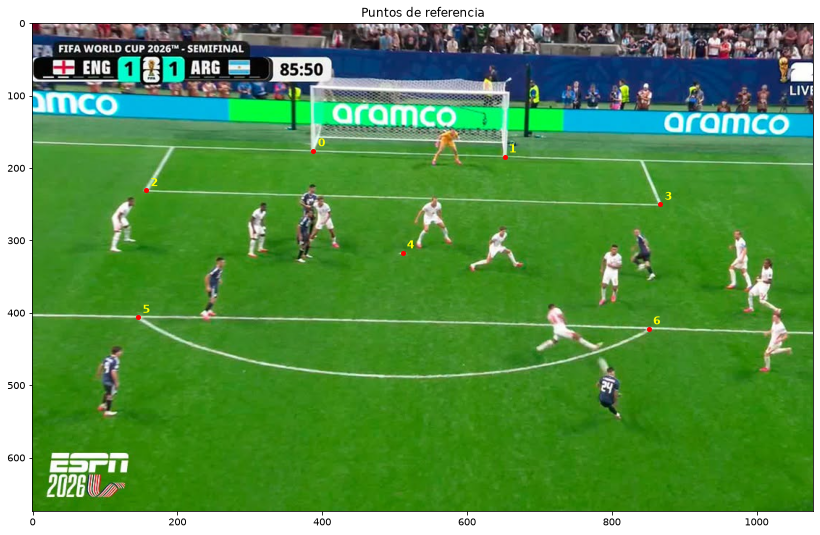

In [3]:
plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(imgPts[:, 0], imgPts[:, 1], 'ro', markersize=4)
for i in range(imgPts.shape[0]):
    plt.text(imgPts[i, 0] + 6, imgPts[i, 1] - 6, str(i), color='yellow', fontsize=11, weight='bold')
plt.title('Puntos de referencia')
plt.show()

### Homografía H (cancha -> imagen) y su inversa

In [4]:
H = ejercicio3.resolverDLT2D(imgPts, objPts)
H_inv = alc.inversa(H)
print(H / H[2, 2])

[[-9.53430528e+00  3.75647469e+01 -7.34465042e+02]
 [ 7.85950305e+00  1.32071472e+00  1.41846393e+02]
 [-1.67225447e-02  1.23844362e-03  1.00000000e+00]]


### Validación
Proyectamos el área chica. Sus esquinas sobre la línea de meta, (0, 24.84) y (0, 43.16), no se usaron para estimar H.

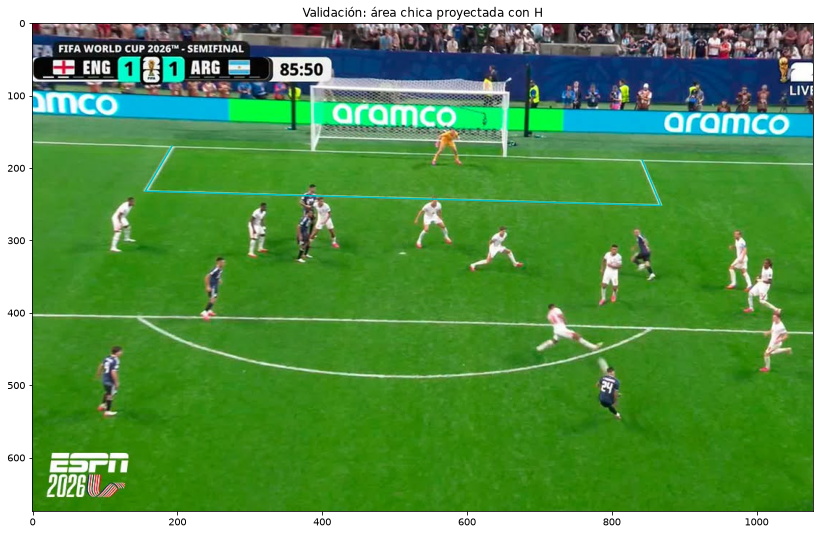

In [5]:
area_chica = ejercicio4.aplicarHomografia(H, np.array([[0.0, 24.84], [5.5, 24.84], [5.5, 43.16], [0.0, 43.16]]))

plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(area_chica[:, 0], area_chica[:, 1], 'c-', linewidth=1.5)
plt.title('Validación: área chica proyectada con H')
plt.show()

### Posición de Enzo y distancia a la línea del arco

In [6]:
pie_enzo_img = ejercicio4.pie_enzo_img
U_enzo, V_enzo = ejercicio4.aplicarHomografia(H_inv, pie_enzo_img)[0]
punto_gol = ejercicio4.punto_gol   # (0, 31): donde entró la pelota
distancia = np.sqrt((U_enzo - punto_gol[0])**2 + (V_enzo - punto_gol[1])**2)
print(f'Enzo en la cancha: U = {U_enzo:.2f} m, V = {V_enzo:.2f} m')
print(f'Distancia al arco (punto donde entró la pelota): {distancia:.2f} m')

Enzo en la cancha: U = 22.24 m, V = 39.80 m
Distancia al arco (punto donde entró la pelota): 23.92 m


In [7]:
linea_arco = np.array([[0, 31]])
u_arco, v_arco = ejercicio4.aplicarHomografia(H, linea_arco)[0]

print(f'Punto de referencia en imagen - Linea del Arco:')
print(f'U = {linea_arco[0][0]:.2f} m, V = {linea_arco[0][1]:.2f} m')
print(f'u = {u_arco:.2f}, v = {v_arco:.2f}')

Punto de referencia en imagen - Linea del Arco:
U = 0.00 m, V = 31.00 m
u = 414.14, v = 176.03


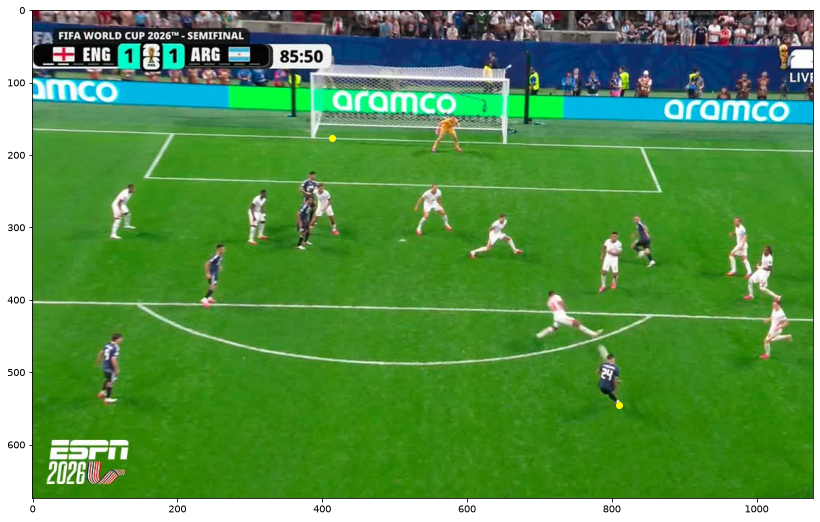

In [8]:
plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(pie_enzo_img[0][0], pie_enzo_img[0][1], 'o', color='yellow', markersize=6)
plt.plot(u_arco, v_arco, 'o', color='yellow', markersize=6)
plt.show()

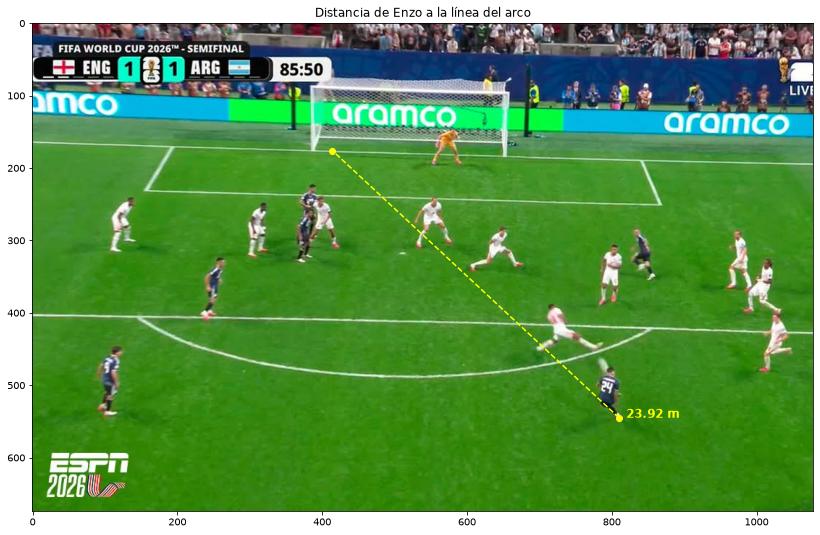

In [9]:
linea_enzo_arco = np.array([[pie_enzo_img[0, 0], u_arco], [pie_enzo_img[0,1], v_arco]])

plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(pie_enzo_img[0, 0], pie_enzo_img[0, 1], 'o', color='yellow', markersize=6)
plt.plot(u_arco, v_arco, 'o', color='yellow', markersize=6)
plt.plot(linea_enzo_arco[0], linea_enzo_arco[1], '--', color='yellow', linewidth=1.5)
plt.text(pie_enzo_img[0, 0] + 10, pie_enzo_img[0, 1], f'{distancia:.2f} m', color='yellow', fontsize=12, weight='bold')
plt.title('Distancia de Enzo a la línea del arco')
plt.show()

## 4.b - Círculos de 1m de radio alrededor de los jugadores argentinos
Misma $\mathbf{H}$ del 4.a.

In [10]:
pies_argentinos_img = ejercicio4.pies_argentinos_img
pies_cancha = ejercicio4.aplicarHomografia(H_inv, pies_argentinos_img)
for i in range(pies_cancha.shape[0]):
    print(f'Jugador {i}: U = {pies_cancha[i, 0]:.2f} m, V = {pies_cancha[i, 1]:.2f} m')

Jugador 0: U = 22.53 m, V = 27.14 m
Jugador 1: U = 16.33 m, V = 28.65 m
Jugador 2: U = 9.79 m, V = 31.07 m
Jugador 3: U = 11.83 m, V = 30.94 m
Jugador 4: U = 12.59 m, V = 41.85 m
Jugador 5: U = 22.24 m, V = 39.80 m


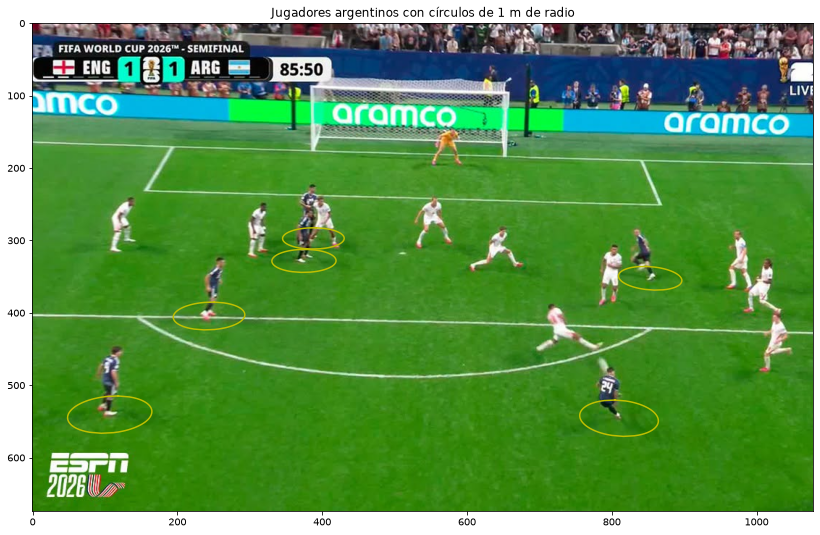

In [11]:
plt.figure(figsize=(14, 9))
plt.imshow(img)
for i in range(pies_cancha.shape[0]):
    circulo_img = ejercicio4.aplicarHomografia(H, ejercicio4.circuloEnCancha(pies_cancha[i], 1.0, 50))
    plt.plot(circulo_img[:, 0], circulo_img[:, 1], 'y-', linewidth=1.5)
plt.title('Jugadores argentinos con círculos de 1 m de radio')
plt.show()

Chequeo: el jugador sobre la línea del área da $U \approx 16.33$ m (real: $16.5$ m).

## 4.c - Posible fuera de juego
Es otra foto, así que estimamos una $\mathbf{H}$ nueva.

In [12]:
img_offside = mpimg.imread(f'{filepath_base}/test-fuera-de-juego.png')
objPts_offside = ejercicio4.objPts_offside
imgPts_offside = ejercicio4.imgPts_offside

H_off = ejercicio3.resolverDLT2D(imgPts_offside, objPts_offside)
H_off_inv = alc.inversa(H_off)
print(H_off / H_off[2, 2])

[[ 8.86024947e+01  1.75955978e+01 -7.13755225e+03]
 [-9.39970715e-01 -6.46638145e+00  1.14738135e+03]
 [-4.25813430e-04  2.38092465e-02  1.00000000e+00]]


### Validación
Línea de fondo, banda de arriba y lado de arriba del área grande.

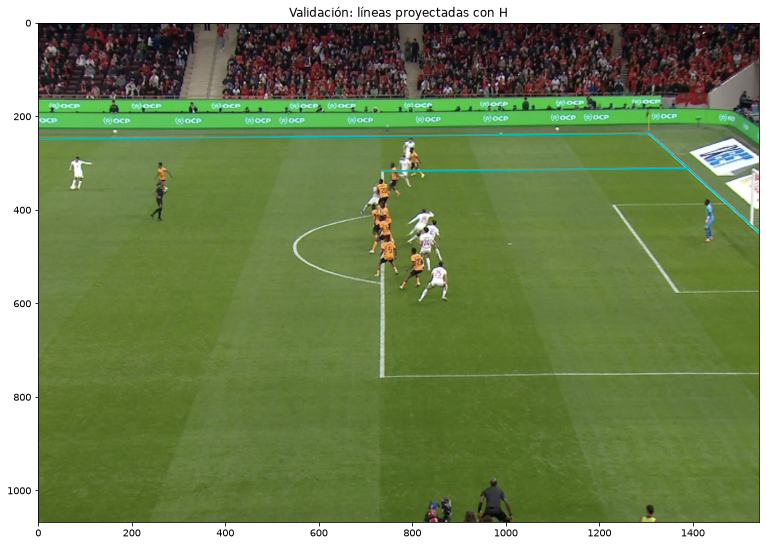

In [13]:
plt.figure(figsize=(14, 9))
plt.imshow(img_offside)
for segmento in [[[105.0, 20.0], [105.0, 68.0]], [[60.0, 68.0], [105.0, 68.0]], [[88.5, 54.16], [105.0, 54.16]]]:
    segmento_img = ejercicio4.aplicarHomografia(H_off, np.array(segmento))
    plt.plot(segmento_img[:, 0], segmento_img[:, 1], 'c-', linewidth=1.5)
plt.xlim(0, img_offside.shape[1])
plt.ylim(img_offside.shape[0], 0)
plt.title('Validación: líneas proyectadas con H')
plt.show()

### Último defensor
El penúltimo en $U$ contando al arquero.

In [14]:
pies_defensores_img = ejercicio4.pies_defensores_img
U_defensores = ejercicio4.aplicarHomografia(H_off_inv, pies_defensores_img)[:, 0]

# El arquero es el de mayor U; el último defensor, el de mayor U entre los demás
i_arquero = 0
for i in range(U_defensores.shape[0]):
    if U_defensores[i] > U_defensores[i_arquero]:
        i_arquero = i
i_ultimo = -1
for i in range(U_defensores.shape[0]):
    if i != i_arquero and (i_ultimo == -1 or U_defensores[i] > U_defensores[i_ultimo]):
        i_ultimo = i
U_ultimo = U_defensores[i_ultimo]
for i in range(U_defensores.shape[0]):
    print(f'Defensor {i}: U = {U_defensores[i]:.2f} m')
print(f'Último defensor: {i_ultimo}, U = {U_ultimo:.2f} m')

Defensor 0: U = 102.42 m
Defensor 1: U = 90.68 m
Defensor 2: U = 89.23 m
Defensor 3: U = 89.16 m
Defensor 4: U = 89.91 m
Último defensor: 1, U = 90.68 m


### Atacantes y recta del último defensor

In [15]:
pies_atacantes_img = ejercicio4.pies_atacantes_img
U_atacantes = ejercicio4.aplicarHomografia(H_off_inv, pies_atacantes_img)[:, 0]
for i in range(U_atacantes.shape[0]):
    diferencia = U_atacantes[i] - U_ultimo
    estado = 'ADELANTADO' if diferencia > 0 else 'habilitado'
    print(f'Atacante {i}: U = {U_atacantes[i]:.2f} m, diferencia = {diferencia:+.2f} m -> {estado}')

Atacante 0: U = 89.83 m, diferencia = -0.85 m -> habilitado
Atacante 1: U = 89.55 m, diferencia = -1.13 m -> habilitado
Atacante 2: U = 90.24 m, diferencia = -0.44 m -> habilitado
Atacante 3: U = 91.00 m, diferencia = +0.32 m -> ADELANTADO
Atacante 4: U = 90.87 m, diferencia = +0.19 m -> ADELANTADO


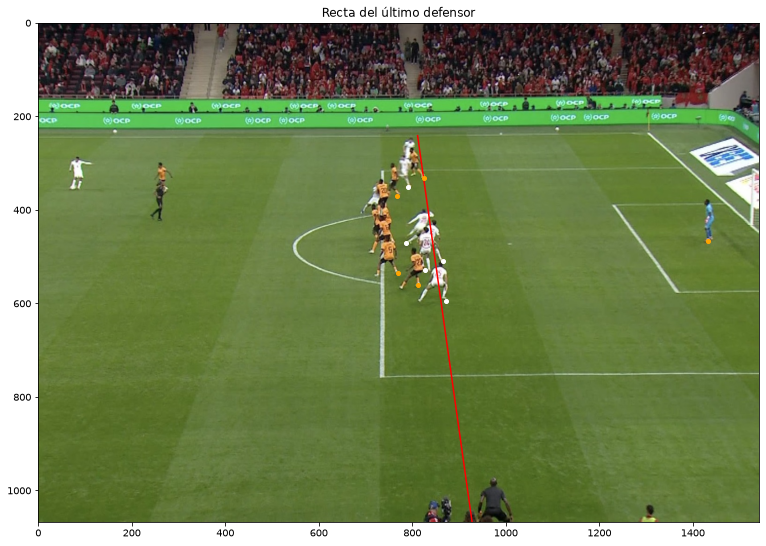

In [16]:
recta_img = ejercicio4.aplicarHomografia(H_off, np.array([[U_ultimo, 0.0], [U_ultimo, 68.0]]))

plt.figure(figsize=(14, 9))
plt.imshow(img_offside)
plt.plot(recta_img[:, 0], recta_img[:, 1], 'r-', linewidth=1.5)
plt.plot(pies_defensores_img[:, 0], pies_defensores_img[:, 1], 'o', color='orange', markersize=4)
plt.plot(pies_atacantes_img[:, 0], pies_atacantes_img[:, 1], 'wo', markersize=4)
plt.xlim(0, img_offside.shape[1])
plt.ylim(img_offside.shape[0], 0)
plt.title('Recta del último defensor')
plt.show()

### Conclusión
Hay fuera de juego: dos atacantes quedan por delante de la recta ($+0.32$ m y $+0.19$ m). Es muy ajustado, del orden del error de marcar los pies a mano.